# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [106]:
STUDENT_NAME = 'Бугай Софія Володимирівна'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 2      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 2: Київ, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [107]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [108]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [109]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_київ


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [110]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [111]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    b0 = cache_bytes()
    t0 = time.time()

    g = getter()
    g = clean(g)
    g.to_parquet(path)

    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 3)}
    return g

In [112]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 826.8 км²


In [113]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 178379 | ребер 521248


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [114]:
# cost_live = pd.DataFrame(COST).T
# cost_live.to_csv(os.path.join(OUT, 'cost_live.csv'), encoding='utf-8')
# display(cost_live)

In [115]:
cost_snap = pd.DataFrame(COST).T
display(cost_snap)

assert (cost_snap['спосіб'] == 'знімок').all()
assert (cost_snap['передано_МБ'].astype(float) == 0).all()

cost_live = pd.read_csv(os.path.join(OUT, 'cost_live.csv'), index_col=0)
t_live = cost_live['секунд'].astype(float).sum()
t_snap = cost_snap['секунд'].astype(float).sum()
mb_saved = cost_live['передано_МБ'].astype(float).sum()

print(f'Живий запит: {t_live:.2f} с | знімок: {t_snap:.2f} с')
print(f'Читання знімка швидше у {t_live / t_snap:.2f} раз(ів)')
print(f'Не передано мережею: {mb_saved:.1f} МБ')

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.05,0.038
heritage,знімок,2749,0.0,0.559,0.098
stations,знімок,149,0.0,0.104,0.052
amenities,знімок,3729,0.0,0.46,0.095
мережа walk,знімок,699627,0.0,35.928,1.481


Живий запит: 2.36 с | знімок: 1.76 с
Читання знімка швидше у 1.34 раз(ів)
Не передано мережею: 0.0 МБ


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [116]:
# ----- ВАШ КОД -----
has_tags = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
has_name = heritage['name'].notna() & (heritage['name'].str.strip() != '')

cand = heritage[has_tags & has_name]
cand = cand.reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(has_tags.sum()))
print('з них мають name       :', len(cand))

усього у шарі heritage : 2749
підходять за тегами    : 2749
з них мають name       : 2156


In [117]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial    969
aircraft    102
ruins        53
cannon       49
building     45
tank         44
vehicle      41
monument     35
yes          15
heritage     13

=== tourism ===
tourism
artwork        386
attraction     242
museum         164
viewpoint       29
gallery         22
information      2
no               2
memorial         1
yes              1

типи геометрії: {'Point': 1895, 'Polygon': 257, 'LineString': 3, 'MultiPolygon': 1}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [118]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# ----- ВАШ КОД -----
has_wd = cand['wikidata'].notna() if 'wikidata' in cand else False
has_wp = cand['wikipedia'].notna() if 'wikipedia' in cand else False
cand['wiki'] = (has_wd | has_wp).astype(int)

lang_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)

cand['visit'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)

cand['hist'] = cand['historic'].notna().astype(int)

cand['area_rank'] = cand['area_m2'].rank(pct=True)

cand['lang_rank'] = cand['n_lang'].rank(pct=True)

W = {'wiki': 0.35, 'lang_rank': 0.25, 'visit': 0.20, 'hist': 0.15, 'area_rank': 0.05}

cand['score'] = (W['wiki'] * cand['wiki']
                 + W['lang_rank'] * cand['lang_rank']
                 + W['visit'] * cand['visit']
                 + W['hist'] * cand['hist']
                 + W['area_rank'] * cand['area_rank'])

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мають переклади:', int((cand['n_lang'] > 0).sum()))
display(cand.sort_values('score', ascending=False)[['name', 'historic', 'tourism', 'wiki', 'n_lang', 'area_m2', 'score']].head(15))

кандидатів   : 2156
мають wiki   : 180
мають переклади: 1932


,name,historic,tourism,wiki,n_lang,area_m2,score
1902,Софійський монастир,monastery,museum,1,14,49620.747898,0.999606
1959,Золоті ворота,city_gate,museum,1,7,512.920560,0.996881
1980,Національний художній музей України,NaN,museum,1,6,1823.755818,0.847391
1957,Національний музей Тараса Шевченка,NaN,museum,1,5,1356.412795,0.846139
1965,Музей «Чорнобиль»,NaN,museum,1,5,954.493510,0.845768
2050,Музей історії Києва,NaN,museum,1,5,815.569762,0.845628
1989,Музей Івана Гончара,NaN,museum,1,4,2046.115800,0.840480
1981,Національний музей історії України,NaN,museum,1,4,1657.265070,0.840387
1958,Національний музей літератури України,NaN,museum,1,4,1273.783237,0.840155
1977,Будинок митрополита,NaN,museum,1,4,1054.719083,0.839947


### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [119]:
N_SMALL, N_LARGE = 10, 30

# ----- ВАШ КОД -----
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
key = lambda d: set(zip(d['element'], d['id']))
overlap = len(key(top10) & key(top_naive))
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за моїми критеріями': list(top10['name']),
                      'за площею': list(top_naive['name'])}))

перетин: 1 з 10


,за моїми критеріями,за площею
0,Софійський монастир,Китаївський археологічний комплекс
1,Золоті ворота,Києво-Печерська цитадель
2,Національний художній музей України,Бабин Яр
3,Національний музей Тараса Шевченка,Київська фортеця
4,Музей «Чорнобиль»,Державний музей авіації
5,Музей історії Києва,Недобудований асфальтовий завод
6,Музей Івана Гончара,Парк воїнів-інтернаціоналістів
7,Національний музей історії України,Софійський монастир
8,Національний музей літератури України,Михайлівський Золотоверхий монастир
9,Будинок митрополита,Городище XII


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [120]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----
pairs = close_pairs(top_score)
print('пар ближче 60 м:', len(pairs))

rows = []
for i, j, d in pairs:
    a, b = top_score.iloc[i], top_score.iloc[j]
    rows.append({
        'об\'єкт A': a['name'], 'тип A': a['historic'] if pd.notna(a['historic']) else a['tourism'],
        'score A': round(a['score'], 3),
        'об\'єкт B': b['name'], 'тип B': b['historic'] if pd.notna(b['historic']) else b['tourism'],
        'score B': round(b['score'], 3),
        'відстань, м': round(d, 1),
    })

pairs_df = pd.DataFrame(rows)
display(pairs_df)

пар ближче 60 м: 1


,об'єкт A,тип A,score A,об'єкт B,тип B,score B,"відстань, м"
0,Музей книги та друкарства України,museum,0.824,Музей історичних коштовностей України,museum,0.813,57.3


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [121]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 149
                         name  railway building
0   Київ-Пасажирський-Дитячий  station      NaN
1              Проспект Науки     halt      NaN
2                       Алмаз     halt      NaN
3                Дарниця-Депо     halt      NaN
4                        ДВРЗ     halt      NaN
5              Караваєві Дачі     halt      NaN
6                   Заводська  station      NaN
7                 Протасів Яр     halt      NaN
8            Київ-Деміївський  station      NaN
9                 Лівобережна     halt      NaN
10                    Дарниця  station      NaN
11                  Лісництво     halt      NaN


In [122]:
# ----- ВАШ КОД -----
st = stations.copy()
st = st[st['name'].notna()]

is_station = (st['railway'] == 'station') if 'railway' in st else False
cand_st = st[is_station]
if cand_st.empty:
    cand_st = st

lang_cols = [c for c in cand_st.columns if c.startswith('name:')]
cand_st = cand_st.assign(
    _lang=cand_st[lang_cols].notna().sum(axis=1),
    _wiki=(cand_st['wikidata'].notna() if 'wikidata' in cand_st else False).astype(int),
)
station = cand_st.sort_values(['_wiki', '_lang'], ascending=False).head(1).reset_index(drop=True)

In [123]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 178379 вузлів, 514774 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [124]:
def check_snap(points, ids, dist, label):
    ids = np.asarray(ids)
    dist = np.asarray(dist, dtype=float)

    n_pts = len(points)
    n_nodes = len(set(ids.tolist()))

    print(f'[{label}] точок: {n_pts} | різних вузлів: {n_nodes}')
    print(f'[{label}] відстань точка → вузол: медіана {np.median(dist):.1f} м, '
          f'максимум {dist.max():.1f} м')

    merged = {}
    if n_nodes < n_pts:
        tmp = pd.DataFrame({'name': points['name'].values, 'node': ids})
        for node, grp in tmp.groupby('node'):
            if len(grp) > 1:
                merged[int(node)] = grp['name'].tolist()
        print(f'[{label}] УВАГА: {n_pts - n_nodes} точок злилися з іншими. Злиті групи:')
        for node, names in merged.items():
            print(f'   вузол {node}: ' + ' | '.join(names))
    else:
        print(f'[{label}] ок: кожна точка має власний вузол')

    return {'точок': n_pts, 'вузлів': n_nodes,
            'медіана_м': float(np.median(dist)), 'макс_м': float(dist.max()),
            'злиті': merged}

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [125]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    # ----- ВАШ КОД: матриця прямих віддалей у метрах -----
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    E = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    return E


def detour_factor(D, E):
    # ----- ВАШ КОД: медіана відношення дорога / пряма, по скінченних парах -----
    iu = np.triu_indices_from(D, k=1)
    d, e = D[iu], E[iu]
    ok = np.isfinite(d) & (e > 0)
    return float(np.median(d[ok] / e[ok]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [126]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

[мала задача] точок: 11 | різних вузлів: 11
[мала задача] відстань точка → вузол: медіана 14.8 м, максимум 30.0 м
[мала задача] ок: кожна точка має власний вузол
матриця за 11.021 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.27


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [127]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    unvisited = set(range(1, k))
    tour = [0]
    cur = 0
    while unvisited:
        nxt = min(unvisited, key=lambda j: D[cur][j])
        tour.append(nxt)
        unvisited.remove(nxt)
        cur = nxt
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                cand = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                L = tour_length(D, cand)
                if L < best_len - 1e-9:
                    best, best_len = cand, L
                    improved = True
    return best

In [128]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [129]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [130]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,15488,10.54
2-opt,14202,1.36
Held-Karp (точний),14011,0.00



оптимальний порядок:
   0. СТАРТ: Майдан Незалежності
   1. Музей «Чорнобиль»
   2. Національний музей історії України
   3. Софійський монастир
   4. Будинок митрополита
   5. Золоті ворота
   6. Національний музей літератури України
   7. Музей історії Києва
   8. Національний музей Тараса Шевченка
   9. Музей Івана Гончара
  10. Національний художній музей України
  11. СТАРТ: Майдан Незалежності

довжина: 14.01 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [131]:
# ----- ВАШ КОД: таблиця зростання -----
ns = [11, 16, 21, 26, 31]

table = []
for n in ns:
    table_size = 2**(n-1)*(n-1)
    memory = 2**(n-31)*(n-1)*8
    table.append({'n': n,'розмір': table_size, 'к-сть гігабайтів': memory})
display(pd.DataFrame(table).set_index('n'))

,розмір,к-сть гігабайтів
n,,
11,10240,0.000076
16,491520,0.003662
21,20971520,0.156250
26,838860800,6.250000
31,32212254720,240.000000


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [132]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

[велика задача] точок: 31 | різних вузлів: 31
[велика задача] відстань точка → вузол: медіана 18.5 м, максимум 109.9 м
[велика задача] ок: кожна точка має власний вузол
коефіцієнт обходу: 1.25
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    55734 м
2-opt            :    49211 м  за 0.019 с  (коротше на 11.7%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м


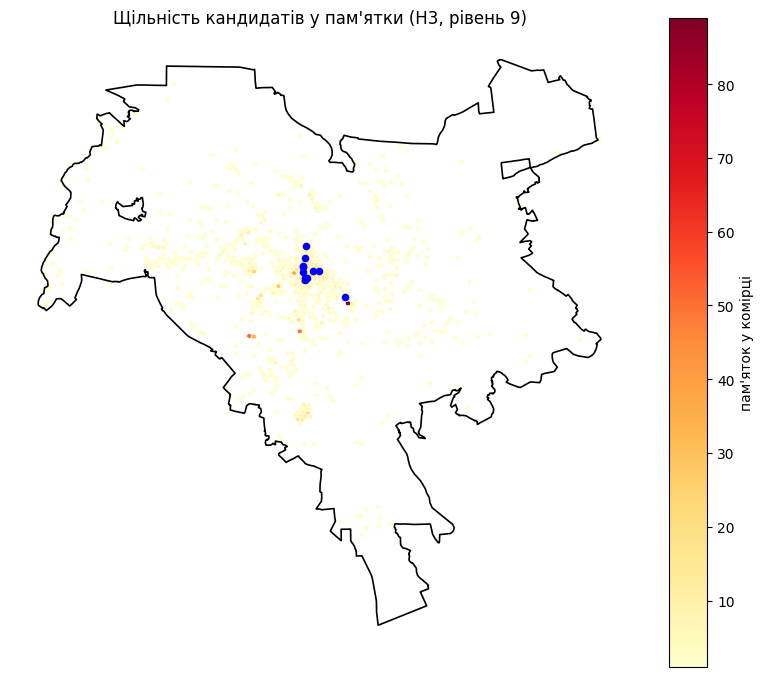

In [133]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
import matplotlib.pyplot as plt

rp = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in rp]

dens = cand['h3'].value_counts().rename_axis('h3').reset_index(name='n')

def hex_poly(cell):
    return Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(cell)])

hexes = gpd.GeoDataFrame(dens, geometry=[hex_poly(c) for c in dens['h3']],
                         crs='EPSG:4326')

fig, ax = plt.subplots(figsize=(10, 10))
hexes.plot(column='n', cmap='YlOrRd', legend=True, edgecolor='white',
           linewidth=0.3, ax=ax, legend_kwds={'label': 'пам\'яток у комірці'})
boundary.boundary.plot(ax=ax, color='black', linewidth=1.2)
pts10.plot(ax=ax, color='blue', markersize=20, zorder=5)
ax.set_title('Щільність кандидатів у пам\'ятки (H3, рівень %d)' % H3_RES)
ax.set_axis_off()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

In [134]:
s = dens['n'].sort_values(ascending=False).reset_index(drop=True)
k_half = int((s.cumsum() / s.sum() < 0.5).sum() + 1)
print('комірок усього:', len(s), '| половина пам\'яток у', k_half, 'комірках',
      '(%.0f%% комірок)' % (100 * k_half / len(s)))

комірок усього: 747 | половина пам'яток у 76 комірках (10% комірок)


---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [135]:
# ----- ВАШ КОД -----
pts_m = pts10.to_crs(32635)[['name', 'geometry']].copy()
am_m = amenities.to_crs(32635)[['name', 'amenity', 'geometry']].copy()
am_m = am_m.rename(columns={'name': 'заклад', 'amenity': 'тип'})

# полігони/лінії заміняємо на репрезентативну точку, щоб відстань була до місця
am_m['geometry'] = am_m.geometry.representative_point()

near = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='відстань_м')
near = near[~near.index.duplicated(keep='first')]   # при нічиїх лишаємо один заклад

display(near[['name', 'заклад', 'тип', 'відстань_м']]
        .rename(columns={'name': 'точка'})
        .round({'відстань_м': 0}))

,точка,заклад,тип,відстань_м
0,СТАРТ: Майдан Незалежності,Aroma Kava,cafe,68.0
1,Софійський монастир,NaN,toilets,67.0
2,Золоті ворота,Porta D'oro,restaurant,51.0
3,Національний художній музей України,Сулугуни,restaurant,50.0
4,Національний музей Тараса Шевченка,Aroma Kava,cafe,114.0
5,Музей «Чорнобиль»,Coffee Dream,cafe,62.0
6,Музей історії Києва,NaN,toilets,4.0
7,Музей Івана Гончара,Таємний сад. Лавра,cafe,77.0
8,Національний музей історії України,NaN,toilets,80.0
9,Національний музей літератури України,Львівські пляцки,cafe,104.0


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [136]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

# ----- ВАШ КОД: folium.Map(..., tiles=BASEMAP), дві PolyLine, маркери з номерами -----
import folium

tour = op10

road = route_coords(tour, ids10)

pts_ll = pts10.to_crs(4326)
straight = [(g.y, g.x) for g in
            (pts_ll.geometry.iloc[i].representative_point() for i in tour)]

fmap = folium.Map(location=road[0], zoom_start=14, tiles=BASEMAP)

folium.PolyLine(road, color='red', weight=5, opacity=0.8,
                tooltip='маршрут по вулицях').add_to(fmap)
folium.PolyLine(straight, color='blue', weight=3, opacity=0.8,
                dash_array='8', tooltip='прямі відрізки').add_to(fmap)

for n, i in enumerate(tour[:-1]):
    p = pts_ll.geometry.iloc[i].representative_point()
    folium.Marker(
        (p.y, p.x), tooltip=pts_ll['name'].iloc[i],
        icon=folium.DivIcon(html=f'<div style="background:#fff;border:2px solid #333;'
                                 f'border-radius:50%;width:24px;height:24px;'
                                 f'text-align:center;line-height:20px;'
                                 f'font-weight:bold">{n}</div>')
    ).add_to(fmap)

fmap.save('lr5_маршрут.html')
fmap

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [137]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.8 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?

На кроці 2 було відкинуто 593 об'єкти. Відкинулись вони через відсутність назви - при першому просіюванні за належністю до дозволених груп, кількість залишилася такою ж самою, вона змінилась тільки після другого етапу просіювання за наявністю назви (об'єкт без назви не можна ні підписати на карті, ні впізнати у маршруті)

2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?

Сигнали й ваги: wikidata/wikipedia 0,35; кількість перекладів назви (ранг) 0,25; tourism=museum/gallery 0,20; historic заповнений 0,15; площа (ранг) 0,05.
Наявність статті — найближче до незалежної оцінки значущості. Переклади відображають інтерес іноземців, але корелюють із wiki, тому вага нижча. Площа — найслабший сигнал (великим буває й склад), тому лише розв'язує нічиї.

3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?

Збігся 1 з 10 (Софійський монастир). За площею вгорі археологічний комплекс, цитадель, Бабин Яр, фортеця, аж «недобудований асфальтовий завод». Це означає, що «найкращі» не властивість даних, а наслідок вибраного критерію: площа міряє розмір, мій рейтинг — визнаність і призначення для відвідування.

4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?

Коефіцієнт обходу: 1,27 (мала задача), 1,25 (велика). Це в типовому діапазоні 1,2-1,6 для пішохідної мережі. Асиметрія матриці 0 м, тобто на пішохідному графі односторонніх ребер немає. Недосяжних пар 0.

5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?

Найближчий сусід гірший за точний розв'язок на 10,54% (15 488 м проти 14 011 м, різниця 1 477 м). 2-opt — на 1,36% (14 202 м). 

6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.

Кількість гігабайтів, потрібна на розв'язок розміром 31, рівна 240 гігабайтам. Кількість пам'ята на середньостатистичному диску С комп'ютера рівна 224 гігабайти, тобто задача потребує на одну таблицю більше пам'яті, ніж може дати простий комп'ютер (чистий, без ніяких даних на ньому).

7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

- 593 об'єкти без назви (21,6%): відкинуто.
- Дублікатів у топі-30 одна пара ближче 60 м (57,3 м): Музей книги та друкарства і Музей історичних коштовностей. Це різні музеї на території Лаври, тому обидва залишено.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [138]:
REPORT = '''
1. Код згенеровано та перевірено
2. Код згенеровано та перевірено
3. Код згенеровано та перевірено
4. Код згенеровано та перевірено
5. Код згенеровано та перевірено
6. Код згенеровано та перевірено
7. Код згенеровано та перевірено

Декларація про використання ШІ: Claude
'''
print(REPORT)


1. Код згенеровано та перевірено
2. Код згенеровано та перевірено
3. Код згенеровано та перевірено
4. Код згенеровано та перевірено
5. Код згенеровано та перевірено
6. Код згенеровано та перевірено
7. Код згенеровано та перевірено

Декларація про використання ШІ: Claude

